## Setup
<!--
- Define paths
- Import libraries
- Set random seed

(Note: I ran this file locally so modify the data folder path accordingly if needed)
-->

In [21]:
import random
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [ ]:
data_folder = Path("/Users/ismailhakkikilic/nlp_cw_2026_ak5323/dontpatronizeme_pcl.tsv")

col_names = ["paragraph_id", "article_id", "keyword", "country_code", "paragraph_text", "pcl_category"]
text_col = "paragraph_text"
label_col = "pcl_category"

In [23]:
def count_words(text):
    return len(str(text).split())

def extract_tokens(text):
    token_pattern = re.compile(r"\b\w+\b")
    return token_pattern.findall(text.lower())


In [24]:
df_raw = pd.read_csv(data_folder, sep="\t", header=None, names=col_names)
df_raw["paragraph_id"] = pd.to_numeric(df_raw["paragraph_id"], errors="coerce")
df_raw["pcl_category"] = pd.to_numeric(df_raw["pcl_category"], errors="coerce")

df_raw["keyword"] = df_raw["keyword"].astype(str).str.strip().str.lower()

df_raw["country_code"] = df_raw["country_code"].astype(str).str.strip().str.lower()
df_raw["paragraph_text"] = df_raw["paragraph_text"].fillna("").astype(str)

In [25]:
df_clean = df_raw.dropna(subset=["paragraph_id", "pcl_category"]).copy()

df_clean["paragraph_id"] = df_clean["paragraph_id"].astype(int)
df_clean["pcl_category"] = df_clean["pcl_category"].astype(int)

In [26]:
df_clean["has_pcl"] = df_clean["pcl_category"].apply(lambda category: "PCL" if category >= 2 else "No PCL")

In [27]:
df_clean.head()

,paragraph_id,article_id,keyword,country_code,paragraph_text,pcl_category,has_pcl
3,1,@@24942188,hopeless,ph,"We 're living in times of absolute insanity , ...",0,No PCL
4,2,@@21968160,migrant,gh,"In Libya today , there are countless number of...",0,No PCL
5,3,@@16584954,immigrant,ie,White House press secretary Sean Spicer said t...,0,No PCL
6,4,@@7811231,disabled,nz,Council customers only signs would be displaye...,0,No PCL
7,5,@@1494111,refugee,ca,""" Just like we received migrants fleeing El Sa...",0,No PCL


In [28]:
df_clean.describe(include="all")

,paragraph_id,article_id,keyword,country_code,paragraph_text,pcl_category,has_pcl
count,10469.000000,10469,10469,10469,10469,10469.000000,10469
unique,NaN,10093,10,20,10469,NaN,2
top,NaN,@@17361342,migrant,za,"We 're living in times of absolute insanity , ...",NaN,No PCL
freq,NaN,9,1089,549,1,NaN,9476
mean,5235.000000,NaN,NaN,NaN,NaN,0.398605,NaN
std,3022.284318,NaN,NaN,NaN,NaN,0.988935,NaN
min,1.000000,NaN,NaN,NaN,NaN,0.000000,NaN
25%,2618.000000,NaN,NaN,NaN,NaN,0.000000,NaN
50%,5235.000000,NaN,NaN,NaN,NaN,0.000000,NaN
75%,7852.000000,NaN,NaN,NaN,NaN,0.000000,NaN


## EDA 1: Class Imbalance Analysis (Keyword & Country Analysis)

In [29]:
empty_text_count = (df_clean["paragraph_text"].str.strip() == "").sum()
empty_text_percentage = (empty_text_count / len(df_clean) * 100) if len(df_clean) > 0 else 0

duplicate_text_count = df_clean["paragraph_text"].duplicated().sum()
duplicate_text_percentage = (duplicate_text_count / len(df_clean) * 100) if len(df_clean) > 0 else 0

binary_label_counts = df_clean["has_pcl"].value_counts().reindex(["No PCL", "PCL"])
binary_label_percentages = (binary_label_counts / len(df_clean) * 100)

detailed_label_counts = df_clean["pcl_category"].value_counts().sort_index()
df_clean["word_count"] = df_clean["paragraph_text"].apply(count_words)

In [30]:
binary_distribution_table = pd.DataFrame({
    "Label": binary_label_counts.index,
    "Count": binary_label_counts.values,
    "Percentage": [f"{p:.2f}%" for p in binary_label_percentages.values]
})

display(binary_distribution_table)

,Label,Count,Percentage
0,No PCL,9476,90.51%
1,PCL,993,9.49%


In [31]:
detailed_distribution_table = pd.DataFrame({
    "Category": [f"Category {cat}" for cat in detailed_label_counts.index],
    "Count": detailed_label_counts.values,
    "Percentage": [f"{(count / len(df_clean) * 100):.2f}%" for count in detailed_label_counts.values]
})
print("\nDetailed PCL Category Distribution:")
display(detailed_distribution_table)

word_stats_data = []
for label in ["No PCL", "PCL"]:
    subset = df_clean[df_clean["has_pcl"] == label]["word_count"]
    word_stats_data.append({
        "Label": label,
        "Mean": f"{subset.mean():.1f}",
        "Median": f"{subset.median():.1f}",
        "Min": subset.min(),
        "Max": subset.max(),
        "Std": f"{subset.std():.1f}"
    })
word_count_stats_table = pd.DataFrame(word_stats_data)
print("\nWord Count Statistics by Label:")
display(word_count_stats_table)


Detailed PCL Category Distribution:


,Category,Count,Percentage
0,Category 0,8529,81.47%
1,Category 1,947,9.05%
2,Category 2,144,1.38%
3,Category 3,458,4.37%
4,Category 4,391,3.73%



Word Count Statistics by Label:


,Label,Mean,Median,Min,Max,Std
0,No PCL,47.9,42.0,0,909,28.6
1,PCL,53.6,47.0,6,512,32.8


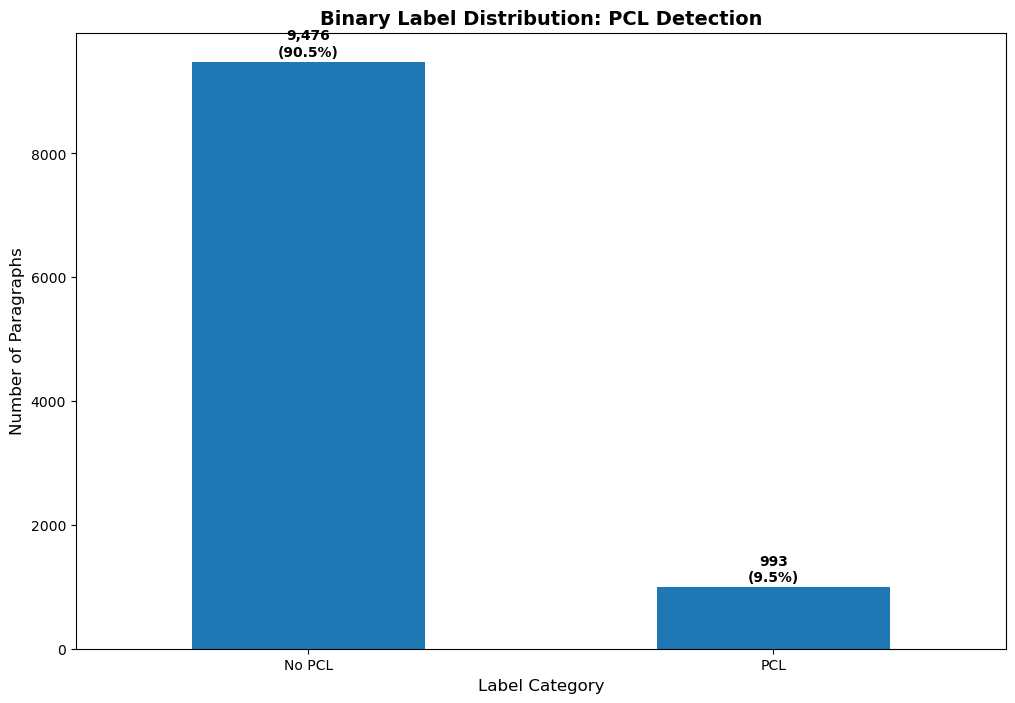

In [32]:
plt.figure(figsize=(12, 8))
binary_label_counts.plot(kind="bar")

plt.title("Binary Label Distribution: PCL Detection", fontsize=14, fontweight='bold')
plt.xlabel("Label Category", fontsize=12)
plt.ylabel("Number of Paragraphs", fontsize=12)
plt.xticks(rotation=0)

for i, (label, count) in enumerate(binary_label_counts.items()):
    plt.text(i, count + 50, f"{count:,}\n({binary_label_percentages[label]:.1f}%)", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')


In [33]:
keyword_analysis = (
    df_clean.groupby(["keyword", "has_pcl"])
    .size()
    .unstack(fill_value=0)
    .reset_index())

keyword_analysis["total_paragraphs"] = keyword_analysis["No PCL"] + keyword_analysis["PCL"]
keyword_analysis["pcl_rate"] = keyword_analysis["PCL"] / keyword_analysis["total_paragraphs"] * 100

keyword_analysis = keyword_analysis.sort_values("total_paragraphs", ascending=False).head(15)

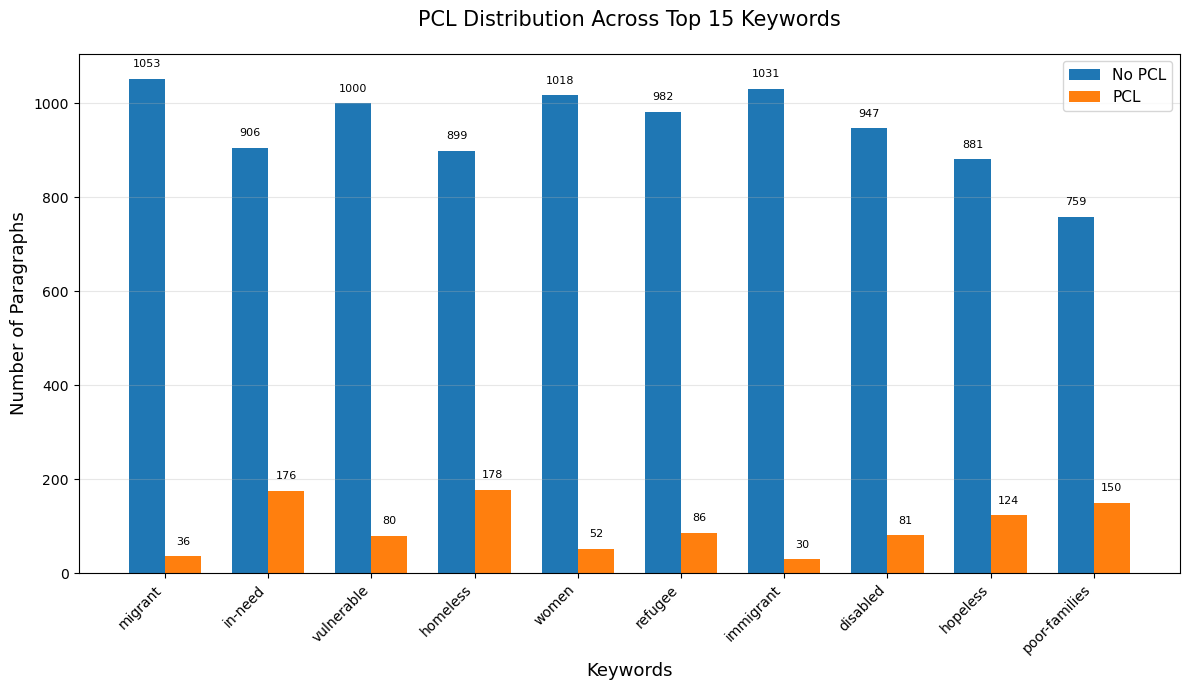

In [34]:
fig, ax = plt.subplots(figsize=(12, 7))
keyword_positions = range(len(keyword_analysis))
bar_width = 0.35

bars_no_pcl = ax.bar(keyword_positions, keyword_analysis["No PCL"],
    bar_width, label="No PCL", linewidth=1)
    
bars_pcl = ax.bar([pos + bar_width for pos in keyword_positions], keyword_analysis["PCL"],
    bar_width, label="PCL", linewidth=1)

for i, (no_pcl, pcl) in enumerate(zip(keyword_analysis["No PCL"], keyword_analysis["PCL"])):
    ax.text(i, no_pcl + 20, str(no_pcl), ha='center', va='bottom', fontsize=8)
    ax.text(i + bar_width, pcl + 20, str(pcl), ha='center', va='bottom', fontsize=8)

ax.set_xlabel("Keywords", fontsize=13)
ax.set_ylabel("Number of Paragraphs", fontsize=13)

ax.set_title("PCL Distribution Across Top 15 Keywords", fontsize=15, pad=20)
ax.set_xticks([pos + bar_width/2 for pos in keyword_positions])
ax.set_xticklabels(keyword_analysis["keyword"], rotation=45, ha='right')

plt.tight_layout()

ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

In [35]:
print("Top 15 Keywords by Total Paragraph Count:")
display(keyword_analysis)

Top 15 Keywords by Total Paragraph Count:


has_pcl,keyword,No PCL,PCL,total_paragraphs,pcl_rate
5,migrant,1053,36,1089,3.305785
4,in-need,906,176,1082,16.266174
8,vulnerable,1000,80,1080,7.407407
1,homeless,899,178,1077,16.527391
9,women,1018,52,1070,4.859813
7,refugee,982,86,1068,8.052434
3,immigrant,1031,30,1061,2.827521
0,disabled,947,81,1028,7.879377
2,hopeless,881,124,1005,12.338308
6,poor-families,759,150,909,16.501650


In [36]:
country_analysis = (
    df_clean.groupby(["country_code", "has_pcl"])
    .size()
    .unstack(fill_value=0)
    .reset_index())

country_analysis["total_paragraphs"] = country_analysis["No PCL"] + country_analysis["PCL"]
country_analysis["pcl_rate"] = country_analysis["PCL"] / country_analysis["total_paragraphs"] * 100

country_analysis = country_analysis[country_analysis["total_paragraphs"] >= 50].sort_values("pcl_rate", ascending=False).head(15)

has_pcl,country_code,No PCL,PCL,total_paragraphs,pcl_rate
4,gh,448,75,523,14.340344
12,ng,465,72,537,13.407821
14,ph,478,67,545,12.293578
8,jm,433,57,490,11.632653
19,za,491,58,549,10.564663
3,gb,483,57,540,10.555556
17,tz,374,41,415,9.879518
15,pk,492,53,545,9.724771
10,lk,455,49,504,9.722222
6,ie,485,52,537,9.683426


Top 15 Countries by PCL Rate:


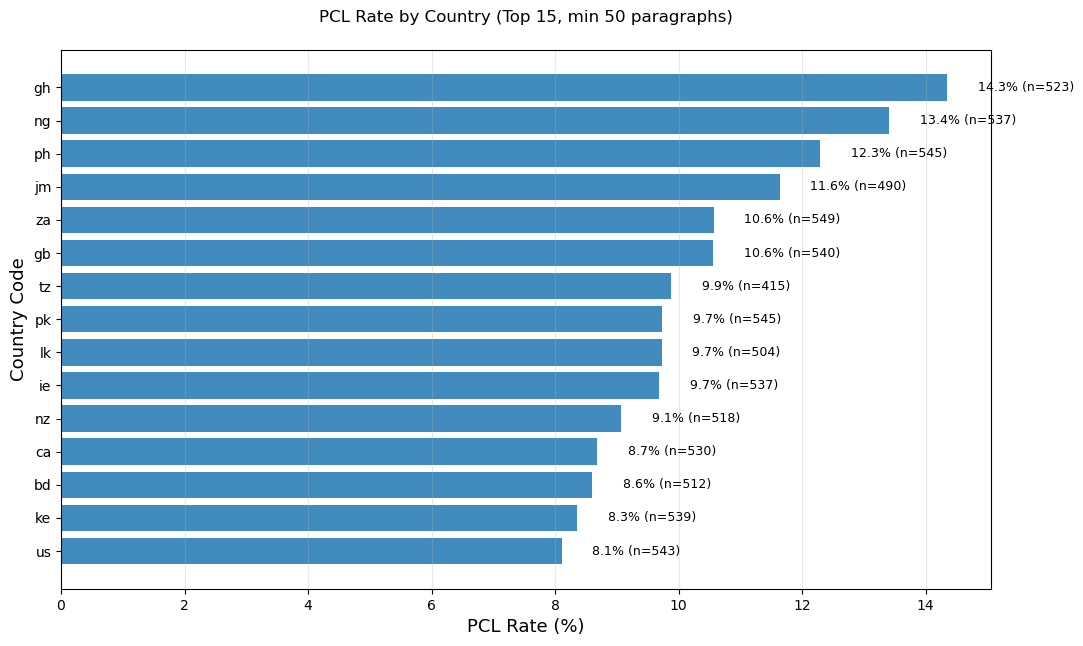

In [37]:
fig, ax = plt.subplots(figsize=(12, 7))
country_positions = range(len(country_analysis))
bars = ax.barh(country_positions, country_analysis["pcl_rate"],  linewidth=1.2, alpha=0.85)

for i, (rate, total) in enumerate(zip(country_analysis["pcl_rate"], country_analysis["total_paragraphs"])):
    ax.text(rate + 0.5, i, f"{rate:.1f}% (n={total})", va='center', fontsize=9)

ax.set_yticks(country_positions)
ax.set_yticklabels(country_analysis["country_code"])

ax.set_xlabel("PCL Rate (%)", fontsize=13)
ax.set_ylabel("Country Code", fontsize=13)
ax.set_title("PCL Rate by Country (Top 15, min 50 paragraphs)", pad=20)

ax.invert_yaxis()
ax.grid(True, alpha=0.3, axis='x')


display(country_analysis)
print("Top 15 Countries by PCL Rate:")

## EDA 2: Word Count Analysis

In [53]:
word_count_stats = []
for label in ["No PCL", "PCL"]:
    subset = df_clean[df_clean["has_pcl"] == label]["word_count"]
    word_count_stats.append({
        "Label": label,
        "Count": len(subset),
        "Mean": f"{subset.mean():.2f}",
        "Median": f"{subset.median():.1f}",
        "Std Dev": f"{subset.std():.2f}",
        "Min": subset.min(),
        "Max": subset.max(),
        "25th %ile": f"{subset.quantile(0.25):.1f}",
        "75th %ile": f"{subset.quantile(0.75):.1f}",
        "90th %ile": f"{subset.quantile(0.90):.1f}"
    })

In [54]:
word_count_stats.append({
    "Label": "Overall",
    "Count": len(df_clean["word_count"]),
    "Mean": f"{df_clean['word_count'].mean():.2f}",
    "Median": f"{df_clean['word_count'].median():.1f}",
    "Std Dev": f"{df_clean['word_count'].std():.2f}",
    "Min": df_clean["word_count"].min(),
    "Max": df_clean["word_count"].max(),
    "25th %ile": f"{df_clean['word_count'].quantile(0.25):.1f}",
    "75th %ile": f"{df_clean['word_count'].quantile(0.75):.1f}",
    "90th %ile": f"{df_clean['word_count'].quantile(0.90):.1f}"
})

In [55]:
word_count_distribution = pd.DataFrame(word_count_stats)
print("Word Count Distribution Statistics:")
display(word_count_distribution)

Word Count Distribution Statistics:


,Label,Count,Mean,Median,Std Dev,Min,Max,25th %ile,75th %ile,90th %ile
0,No PCL,9476,47.88,42.0,28.62,0,909,30.0,59.0,83.0
1,PCL,993,53.62,47.0,32.78,6,512,33.0,67.0,90.0
2,Overall,10469,48.42,42.0,29.09,0,909,30.0,60.0,83.0


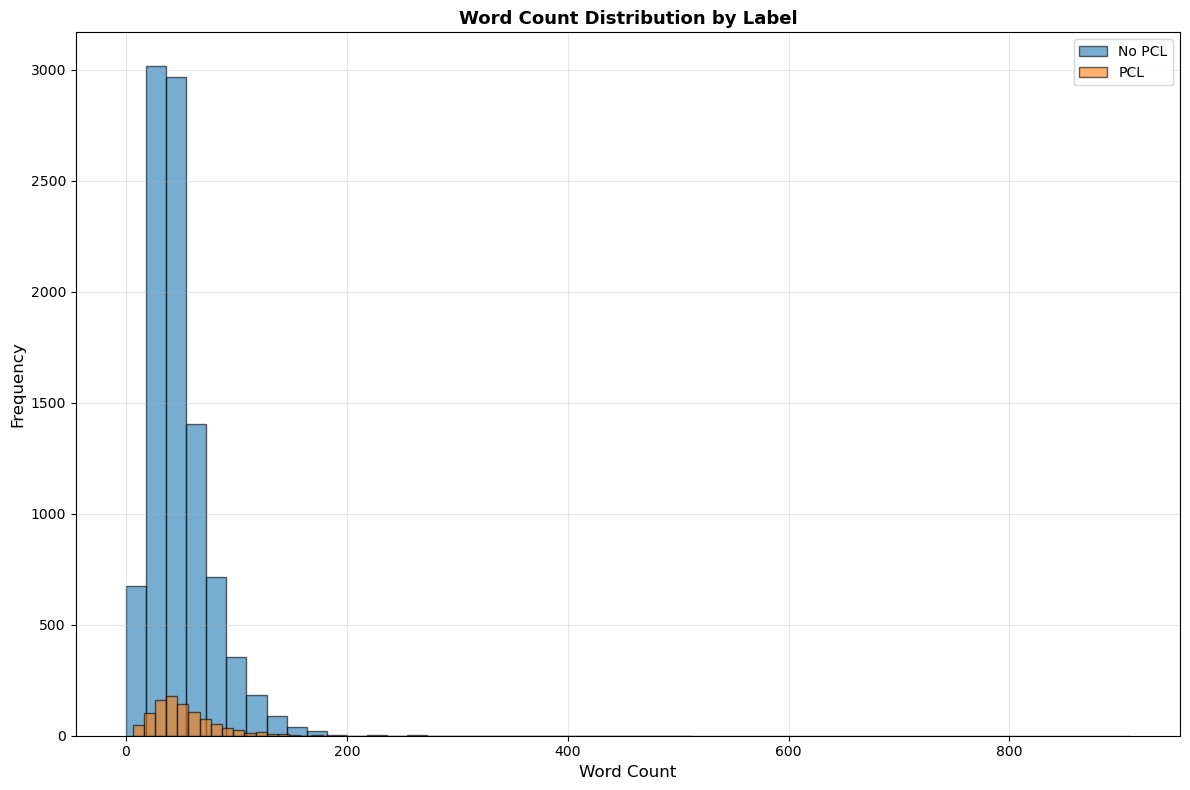

In [44]:
plt.figure(figsize=(12, 8))
for label in ["No PCL", "PCL"]:
    subset = df_clean[df_clean["has_pcl"] == label]["word_count"]
    plt.hist(subset, bins=50, alpha=0.6, label=label, edgecolor='black')

plt.xlabel("Word Count", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Word Count Distribution by Label", fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

<Figure size 1200x800 with 0 Axes>

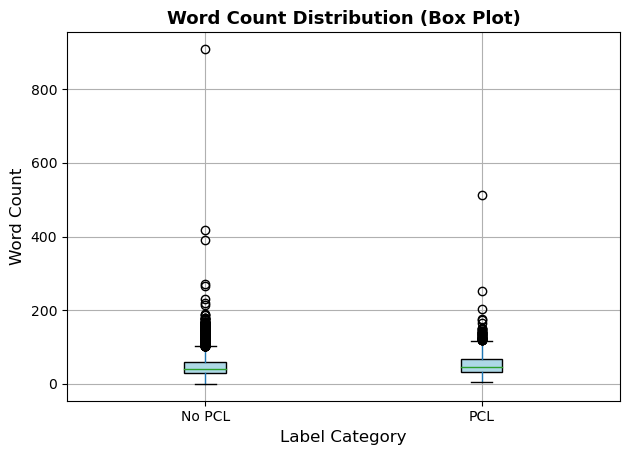

In [45]:
plt.figure(figsize=(12, 8))
df_clean.boxplot(column="word_count", by="has_pcl", patch_artist=True, boxprops=dict(facecolor="lightblue"))
plt.xlabel("Label Category", fontsize=12)
plt.ylabel("Word Count", fontsize=12)
plt.title("Word Count Distribution (Box Plot)", fontsize=13, fontweight='bold')
plt.suptitle("")
plt.tight_layout()